# Titanic Survival: End-to-End Data Mining

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Questions:** Which passenger traits were linked to survival, which patterns are real and which are confounded, and how well can survival be predicted?

**What this notebook covers**
1. Data quality report
2. Exploratory patterns and a confounding check
3. Association rules (support, confidence, lift), implemented from scratch
4. Classification: five models compared with cross-validation
5. Choosing a decision threshold to fit the goal
6. Hyperparameter tuning and a single, final test evaluation
7. Feature engineering experiment and limitations

In [1]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED = 7
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(URL)
titanic.shape

(891, 12)

## 1. Data quality report

In [2]:
quality = pd.DataFrame({"dtype": titanic.dtypes,
                        "missing": titanic.isna().sum(),
                        "missing_%": (titanic.isna().mean() * 100).round(1)}).sort_values("missing", ascending=False)
quality.head(6)

,dtype,missing,missing_%
Cabin,object,687,77.1
Age,float64,177,19.9
Embarked,object,2,0.2
PassengerId,int64,0,0.0
Survived,int64,0,0.0
Pclass,int64,0,0.0


**Cabin** is 77% missing, so it is dropped. **Age** is 20% missing and is imputed from passenger class and sex rather than one overall median.

## 2. Exploratory patterns

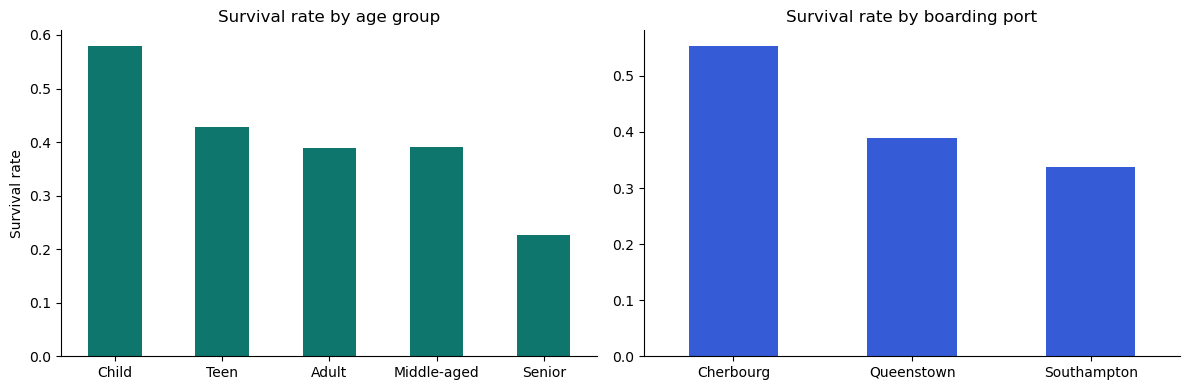

Embarked
Cherbourg      0.554
Queenstown     0.390
Southampton    0.337
Name: Survived, dtype: float64


In [3]:
titanic["AgeGroup"] = pd.cut(titanic["Age"], bins=[0, 12, 18, 40, 60, 80],
                             labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"])
by_age = titanic.groupby("AgeGroup", observed=False)["Survived"].mean()
by_port = titanic.groupby("Embarked")["Survived"].mean().rename({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_age.plot.bar(ax=axes[0], color="#0f766e", rot=0); axes[0].set(title="Survival rate by age group", ylabel="Survival rate", xlabel="")
by_port.plot.bar(ax=axes[1], color="#365bd6", rot=0); axes[1].set(title="Survival rate by boarding port", xlabel="")
plt.tight_layout(); plt.savefig("../images/survival_by_age_and_port.png", dpi=150, bbox_inches="tight"); plt.show()
print(by_port.round(3))

### Is the port effect real? A confounding check
Cherbourg passengers survived far more often. But did the *port* matter, or the *kind of passenger* who boarded there?

In [4]:
pd.crosstab(titanic['Embarked'], titanic['Pclass'], normalize='index').round(3).rename(columns={1: '1st class', 2: '2nd class', 3: '3rd class'})

Pclass,1st class,2nd class,3rd class
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.197,0.255,0.548


About half of Cherbourg passengers travelled first class, versus about one in five from Southampton. **Passenger class, not the port, explains most of the gap.** This is a confounder, and it is why descriptive patterns should not be read as causes.

## 3. Association rules (implemented from scratch)
Each passenger is treated as a *basket* of traits. A rule *A → survived* is scored by **support** (how common), **confidence** (how often survival follows), and **lift** (how much more likely than average).

In [5]:
titanic["FareLevel"] = pd.qcut(titanic["Fare"], 3, labels=["low", "mid", "high"])
def basket_items(r):
    items = {f"class={r.Pclass}", f"sex={r.Sex}", f"fare={r.FareLevel}"}
    if pd.notna(r.Age):
        items.add("age=child" if r.Age < 18 else "age=adult")
    return items
baskets = [basket_items(r) for r in titanic.itertuples()]
survived = titanic["Survived"].astype(bool).to_numpy()
base_rate = survived.mean()

all_items = sorted(set().union(*baskets))
has = {i: np.array([i in b for b in baskets]) for i in all_items}
rules = []
for k in (1, 2, 3, 4):
    for combo in combinations(all_items, k):
        if len({c.split("=")[0] for c in combo}) < k:      # one value per attribute
            continue
        mask = np.logical_and.reduce([has[c] for c in combo])
        support_a = mask.mean()
        if support_a == 0:
            continue
        support = (mask & survived).mean()
        confidence = support / support_a
        if support >= 0.05 and confidence >= 0.7:
            rules.append({"if passenger is": " + ".join(combo), "support": support,
                          "confidence": confidence, "lift": confidence / base_rate})
rules = pd.DataFrame(rules).sort_values(["lift", "support"], ascending=False).round(2).reset_index(drop=True)
print(f"Base survival rate: {base_rate:.1%}")
rules.head(6)

Base survival rate: 38.4%


,if passenger is,support,confidence,lift
0,age=adult + class=1 + sex=female,0.08,0.97,2.54
1,age=adult + class=1 + fare=high + sex=female,0.08,0.97,2.54
2,class=1 + sex=female,0.10,0.97,2.52
3,class=1 + fare=high + sex=female,0.10,0.97,2.52
4,class=2 + sex=female,0.08,0.92,2.40
5,age=adult + fare=high + sex=female,0.10,0.90,2.36


Women in first class survived **97%** of the time, about **2.5×** the average passenger. A high lift with low confidence would not pass the 0.7 confidence threshold, which is why the simple *fare=high* rule (lift ≈ 1.5, confidence ≈ 0.56) does not appear.

## 4. Prepare features and split the data

In [6]:
def prepare(df):
    data = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "AgeGroup", "FareLevel"], errors="ignore").copy()
    data["Age"] = data.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))
    data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
    data["Sex"] = (data["Sex"] == "female").astype(int)
    data = pd.get_dummies(data, columns=["Embarked"], dtype=int)
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    return data

data = prepare(titanic)
X, y = data.drop(columns="Survived"), data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("Training rows:", len(X_train), "| test rows:", len(X_test))

Training rows: 668 | test rows: 223


## 5. Compare five classifiers with 5-fold cross-validation (training data only)

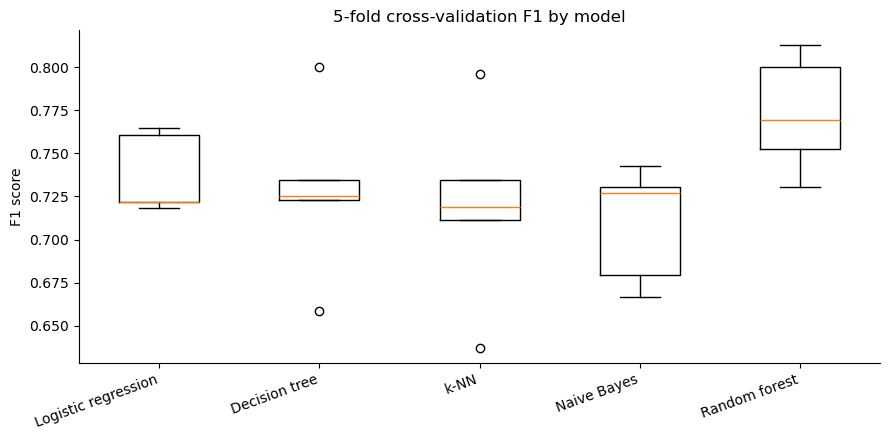

,mean F1,std F1
Random forest,0.773,0.030
Logistic regression,0.737,0.021
Decision tree,0.728,0.045
k-NN,0.720,0.051
Naive Bayes,0.709,0.030


In [7]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Naive Bayes": GaussianNB(),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
}
cv_f1 = {name: cross_val_score(m, X_train, y_train, cv=5, scoring="f1") for name, m in models.items()}
summary = pd.DataFrame({"mean F1": {k: v.mean() for k, v in cv_f1.items()},
                        "std F1": {k: v.std() for k, v in cv_f1.items()}}).sort_values("mean F1", ascending=False).round(3)
plt.figure(figsize=(9, 4.5))
plt.boxplot(list(cv_f1.values()), tick_labels=list(cv_f1.keys()))
plt.xticks(rotation=20, ha="right"); plt.ylabel("F1 score"); plt.title("5-fold cross-validation F1 by model")
plt.tight_layout(); plt.savefig("../images/model_comparison_cv_f1.png", dpi=150, bbox_inches="tight"); plt.show()
summary

## 6. Match the decision threshold to the goal
The default 0.5 threshold is not always right. In a rescue scenario, missing a survivor is worse than a false alarm, so **recall** matters most.

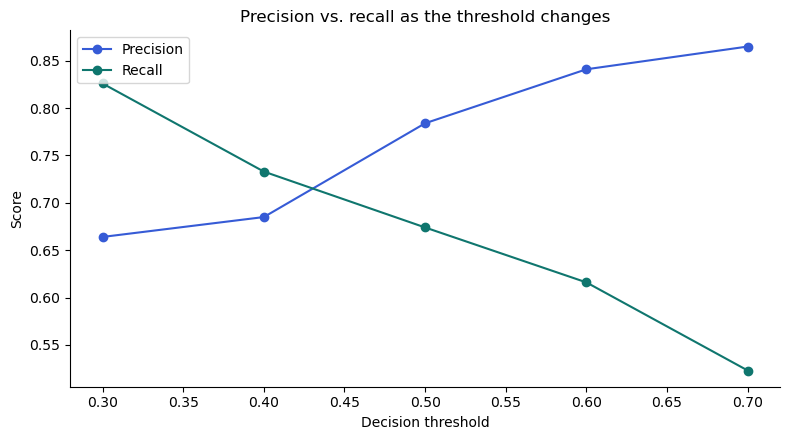

,threshold,precision,recall
0,0.3,0.664,0.826
1,0.4,0.685,0.733
2,0.5,0.784,0.674
3,0.6,0.841,0.616
4,0.7,0.865,0.523


In [8]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
proba = logreg.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred)})
thr = pd.DataFrame(rows).round(3)
plt.plot(thr["threshold"], thr["precision"], "o-", label="Precision", color="#365bd6")
plt.plot(thr["threshold"], thr["recall"], "o-", label="Recall", color="#0f766e")
plt.xlabel("Decision threshold"); plt.ylabel("Score"); plt.title("Precision vs. recall as the threshold changes"); plt.legend()
plt.tight_layout(); plt.savefig("../images/threshold_tradeoff.png", dpi=150, bbox_inches="tight"); plt.show()
thr

A **0.3 threshold** catches the most survivors (highest recall) at the cost of more false alarms. The right threshold depends on the decision being made, not on a default.

## 7. Tune the random forest, then evaluate once on the test set

Best settings: {'max_depth': 7, 'min_samples_leaf': 1, 'n_estimators': 300}
CV F1: 0.775
Test F1: 0.772 | Test accuracy: 0.839


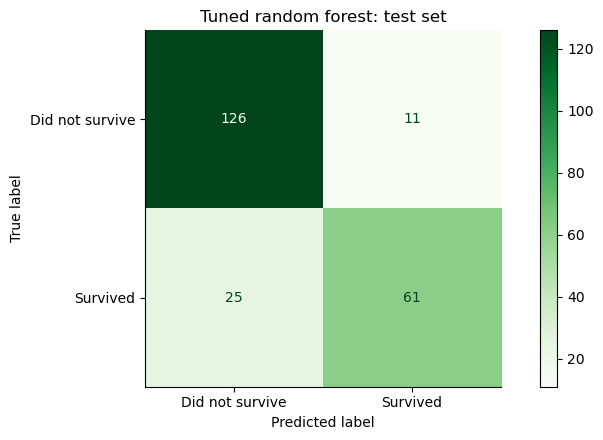

In [9]:
search = GridSearchCV(RandomForestClassifier(random_state=SEED),
                      {"n_estimators": [100, 300], "max_depth": [3, 5, 7, None], "min_samples_leaf": [1, 5]},
                      cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
pred = search.predict(X_test)
print("Best settings:", search.best_params_)
print(f"CV F1: {search.best_score_:.3f}")
print(f"Test F1: {f1_score(y_test, pred):.3f} | Test accuracy: {accuracy_score(y_test, pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Did not survive", "Survived"], cmap="Greens")
plt.title("Tuned random forest: test set"); plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

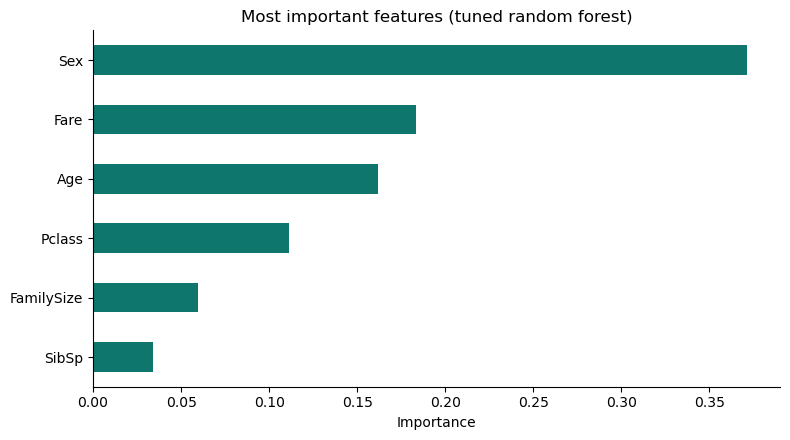

Sex           0.372
Fare          0.183
Age           0.162
Pclass        0.111
FamilySize    0.060
dtype: float64

In [10]:
importance = pd.Series(search.best_estimator_.feature_importances_, index=X_train.columns).sort_values()
importance.tail(6).plot.barh(color="#0f766e")
plt.title("Most important features (tuned random forest)"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
importance.sort_values(ascending=False).head(5).round(3)

## 8. Feature engineering experiment: passenger title
Titles such as *Master* (boys) carry age and status information that *Sex* and *Age* alone miss. Does adding them help?

In [11]:
titles = titanic["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
titles = titles.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
titles = titles.where(titles.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
X_title = pd.concat([X, pd.get_dummies(titles, prefix="Title", dtype=int)], axis=1)
Xt_train = X_title.loc[X_train.index]
rf = RandomForestClassifier(n_estimators=300, max_depth=search.best_params_["max_depth"],
                            min_samples_leaf=search.best_params_["min_samples_leaf"], random_state=SEED)
base = cross_val_score(rf, X_train, y_train, cv=5, scoring="f1").mean()
with_title = cross_val_score(rf, Xt_train, y_train, cv=5, scoring="f1").mean()
print(f"CV F1 without title: {base:.3f} | with title: {with_title:.3f}")

CV F1 without title: 0.775 | with title: 0.764


**Result:** adding titles did **not** improve this model (cross-validated F1 fell slightly). The random forest already recovers most of that signal from sex, age, and fare, so the simpler feature set is kept. Reporting experiments that do not help is part of an honest analysis.

## 9. Conclusions
- **Sex, fare, age, and class** dominate survival, matching the historical "women and children first" policy and the advantage of upper-class cabins.
- **The Cherbourg effect is confounded** by passenger class, a reminder to check before drawing causal conclusions.
- **The tuned random forest** generalizes well; its test score is close to cross-validation.
- **Thresholds are a business decision:** a rescue scenario favors recall over precision.

**Limitations and ethics.** The model learns from one historical event and reflects the social rules of 1912. It should not be used to make decisions about real people; its value is in demonstrating a careful, honest modelling process.